<a href="https://colab.research.google.com/github/HannaVar1/belhard_project/blob/main/02_type_classification_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn

from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

DATA_PATH = Path(
    "/content/drive/MyDrive/datasets/pokemon_complete.csv"
)

B_DIR = Path(
    "/content/drive/MyDrive/classification_results_B"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/classification_final_test"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS_PATH = B_DIR / "classification_models.joblib"
CHECKPOINT_PATH = B_DIR / "mlp_checkpoint.pt"
SPLIT_PATH = B_DIR / "split.csv"

MARKER_PATH = OUTPUT_DIR / "evaluation_started.json"

DEVICE = torch.device("cpu")
sns.set_theme(style="whitegrid")

for path in [
    DATA_PATH, MODELS_PATH, CHECKPOINT_PATH, SPLIT_PATH
]:
    if not path.is_file():
        raise FileNotFoundError(f"Не найден файл: {path}")

# Эти артефакты созданы кодом эксперимента B.
bundle = joblib.load(MODELS_PATH)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True,
)

required_keys = [
    "baseline",
    "svm",
    "mlp_preprocessor",
    "label_encoder",
    "features",
    "numeric_features",
    "categorical_features",
    "target",
]

missing = set(required_keys) - set(bundle)

if missing:
    raise ValueError(
        f"В артефактах B отсутствуют поля: {sorted(missing)}"
    )

baseline_B = bundle["baseline"]
svm_B = bundle["svm"]
preprocessor_B = bundle["mlp_preprocessor"]
encoder_B = bundle["label_encoder"]

FEATURES = bundle["features"]
NUMERIC_FEATURES = bundle["numeric_features"]
CATEGORICAL_FEATURES = bundle["categorical_features"]
TARGET = bundle["target"]
GROUP = "evolution_chain_id"

CLASSES = encoder_B.classes_

if TARGET != "type_1":
    raise ValueError(f"Неожиданная цель: {TARGET}")

if CATEGORICAL_FEATURES != ["color", "shape"]:
    raise ValueError("Загружен не ожидаемый набор признаков B")

if checkpoint["features"] != FEATURES:
    raise ValueError("Признаки checkpoint и preprocessing различаются")

if checkpoint["classes"] != CLASSES.tolist():
    raise ValueError("Порядок классов checkpoint и encoder различается")

if checkpoint["num_classes"] != len(CLASSES):
    raise ValueError("Некорректное число классов checkpoint")

# Архитектура точно повторяет эксперимент B.
mlp_B = nn.Sequential(
    nn.Linear(checkpoint["input_dim"], 64),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, checkpoint["num_classes"]),
).to(DEVICE)

mlp_B.load_state_dict(checkpoint["state_dict"])
mlp_B.eval()

# Нет optimizer, fit или нового обучения.
print("Загружены модели эксперимента B")
print("Лучшая сохранённая эпоха MLP:", checkpoint["best_epoch"])
print("Признаки:", FEATURES)

raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

required_columns = [
    "pokedex_number", "name", TARGET, GROUP, *FEATURES
]

missing = set(required_columns) - set(raw.columns)

if missing:
    raise ValueError(f"В CSV отсутствуют поля: {sorted(missing)}")

raw["pokedex_number"] = pd.to_numeric(
    raw["pokedex_number"], errors="raise"
)

df = raw.loc[
    raw["pokedex_number"].between(1, 1025)
].copy().reset_index(drop=True)

if df.empty or not df["pokedex_number"].is_unique:
    raise ValueError("Пустая выборка или повторяющиеся ID")

if df[[TARGET, GROUP, *FEATURES]].isna().any().any():
    raise ValueError("В используемых данных есть пропуски")

df[TARGET] = df[TARGET].astype(str).str.strip()
df[GROUP] = pd.to_numeric(df[GROUP], errors="raise")

df[NUMERIC_FEATURES] = df[NUMERIC_FEATURES].apply(
    pd.to_numeric, errors="raise"
)

for column in CATEGORICAL_FEATURES:
    df[column] = df[column].astype(str).str.strip()

if df[[TARGET, *CATEGORICAL_FEATURES]].eq("").any().any():
    raise ValueError("Есть пустые категории")

if not np.isfinite(
    df[NUMERIC_FEATURES].to_numpy(dtype=float)
).all():
    raise ValueError("Некорректные числовые значения")

if (df[NUMERIC_FEATURES] < 0).any().any():
    raise ValueError("Отрицательные значения признаков")

# Используйте ту же версию CSV, что в B:
# split.csv не содержит снимок всех значений признаков.

Загружены модели эксперимента B
Лучшая сохранённая эпоха MLP: 44
Признаки: ['hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed', 'height_m', 'weight_kg', 'color', 'shape']


In [ ]:
saved_split = pd.read_csv(
    SPLIT_PATH, encoding="utf-8-sig"
)

required_split = [
    "pokedex_number", "split", TARGET, GROUP
]

missing = set(required_split) - set(saved_split.columns)

if missing:
    raise ValueError(f"В split.csv отсутствуют поля: {sorted(missing)}")

if saved_split[required_split].isna().any().any():
    raise ValueError("Пропуски в split.csv")

saved_split["pokedex_number"] = pd.to_numeric(
    saved_split["pokedex_number"], errors="raise"
)
saved_split[GROUP] = pd.to_numeric(
    saved_split[GROUP], errors="raise"
)
saved_split[TARGET] = saved_split[TARGET].astype(str).str.strip()
saved_split["split"] = saved_split["split"].astype(str).str.strip()

if not saved_split["pokedex_number"].is_unique:
    raise ValueError("Повторяющиеся ID в split.csv")

if set(saved_split["split"]) != {"train", "validation", "test"}:
    raise ValueError("Некорректные части выборки")

if set(saved_split["pokedex_number"]) != set(df["pokedex_number"]):
    raise ValueError("Текущий набор объектов отличается от B")

reference = saved_split.set_index("pokedex_number")
current = df.set_index("pokedex_number")

for column in [TARGET, GROUP]:
    old = reference[column].reindex(current.index)
    if not old.eq(current[column]).fillna(False).all():
        raise ValueError(f"Изменилось поле {column} относительно split B")

# Сохраняем порядок ID из файла разбиения B.
parts = {
    name: current.loc[
        saved_split.loc[
            saved_split["split"] == name, "pokedex_number"
        ].tolist()
    ].reset_index()
    for name in ["train", "validation", "test"]
}

for first, second in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    if set(parts[first][GROUP]) & set(parts[second][GROUP]):
        raise ValueError(f"Пересечение цепочек: {first}/{second}")

test = parts["test"]

if len(test) != 200:
    raise ValueError(
        f"Ожидалось 200 объектов test из B, получено {len(test)}"
    )

unknown_labels = set(test[TARGET]) - set(CLASSES)
if unknown_labels:
    raise ValueError(f"Неизвестные модели типы: {unknown_labels}")

test_counts = (
    test[TARGET].value_counts()
    .reindex(CLASSES, fill_value=0)
)

print("Размер test:", len(test))
print("Количество цепочек:", test[GROUP].nunique())
display(test_counts.to_frame("support"))

absent_classes = test_counts.index[test_counts == 0].tolist()
print("Типы, отсутствующие в test:", absent_classes)


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


protocol = {
    "experiment": "Final test of frozen experiment B",
    "selected_candidate_by_validation": "PyTorch MLP B",
    "comparison_models": ["Dummy B", "SVM RBF B", "PyTorch MLP B"],
    "primary_metric": "macro_f1",
    "macro_f1_labels": CLASSES.tolist(),
    "features": FEATURES,
    "test_rows": len(test),
    "test_chains": int(test[GROUP].nunique()),
    "absent_test_classes": absent_classes,
    "mlp_best_epoch": int(checkpoint["best_epoch"]),
    "files_sha256": {
        "dataset": sha256_file(DATA_PATH),
        "models": sha256_file(MODELS_PATH),
        "checkpoint": sha256_file(CHECKPOINT_PATH),
        "split": sha256_file(SPLIT_PATH),
    },
}

print("Протокол подготовлен. Обучение и подбор параметров не выполняются.")

Размер test: 200
Количество цепочек: 109


,support
type_1,
Bug,18
Dark,5
Dragon,7
Electric,9
Fairy,10
Fighting,10
Fire,14
Flying,0
Ghost,4


Типы, отсутствующие в test: ['Flying']
Протокол подготовлен. Обучение и подбор параметров не выполняются.


Итоговая оценка зафиксированных моделей B:


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,model,accuracy,balanced_accuracy,macro_f1_all_18,macro_f1_present_types,weighted_f1,correct,test_rows
0,Dummy B,0.155,0.0588,0.0149,0.0158,0.0416,31,200
1,SVM RBF B,0.365,0.3003,0.2736,0.2897,0.3926,73,200
2,PyTorch MLP B,0.425,0.3076,0.2836,0.3002,0.4076,85,200



Dummy B: метрики типов


,precision,recall,f1-score,support
Bug,0.000,0.0,0.000,18.0
Dark,0.000,0.0,0.000,5.0
Dragon,0.000,0.0,0.000,7.0
Electric,0.000,0.0,0.000,9.0
Fairy,0.000,0.0,0.000,10.0
Fighting,0.000,0.0,0.000,10.0
Fire,0.000,0.0,0.000,14.0
Flying,0.000,0.0,0.000,0.0
Ghost,0.000,0.0,0.000,4.0
Grass,0.000,0.0,0.000,20.0


Ошибок: 169 из 200


,pokedex_number,name,evolution_chain_id,type_1,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,color,shape,prediction
0,13,Weedle,5,Bug,40,35,30,20,20,50,0.3,3.2,brown,armor,Water
1,14,Kakuna,5,Bug,45,25,50,25,25,35,0.6,10.0,yellow,squiggle,Water
2,15,Beedrill,5,Bug,65,90,40,45,80,75,1.0,29.5,yellow,bug-wings,Water
3,19,Rattata,7,Normal,30,56,35,25,35,72,0.3,3.5,purple,quadruped,Water
4,20,Raticate,7,Normal,55,81,60,50,70,97,0.7,18.5,brown,quadruped,Water
5,35,Clefairy,14,Fairy,70,45,48,60,65,35,0.6,7.5,pink,upright,Water
6,36,Clefable,14,Fairy,95,70,73,95,90,60,1.3,40.0,pink,upright,Water
7,39,Jigglypuff,16,Normal,115,45,20,45,25,20,0.5,5.5,pink,humanoid,Water
8,40,Wigglytuff,16,Normal,140,70,45,85,50,45,1.0,12.0,pink,humanoid,Water
9,50,Diglett,21,Ground,10,55,25,35,45,95,0.2,0.8,brown,blob,Water


Самые частые пары ошибок:


,,count
type_1,prediction,
Normal,Water,23
Grass,Water,20
Bug,Water,18
Fire,Water,14
Psychic,Water,13
Fairy,Water,10
Fighting,Water,10
Electric,Water,9
Rock,Water,9


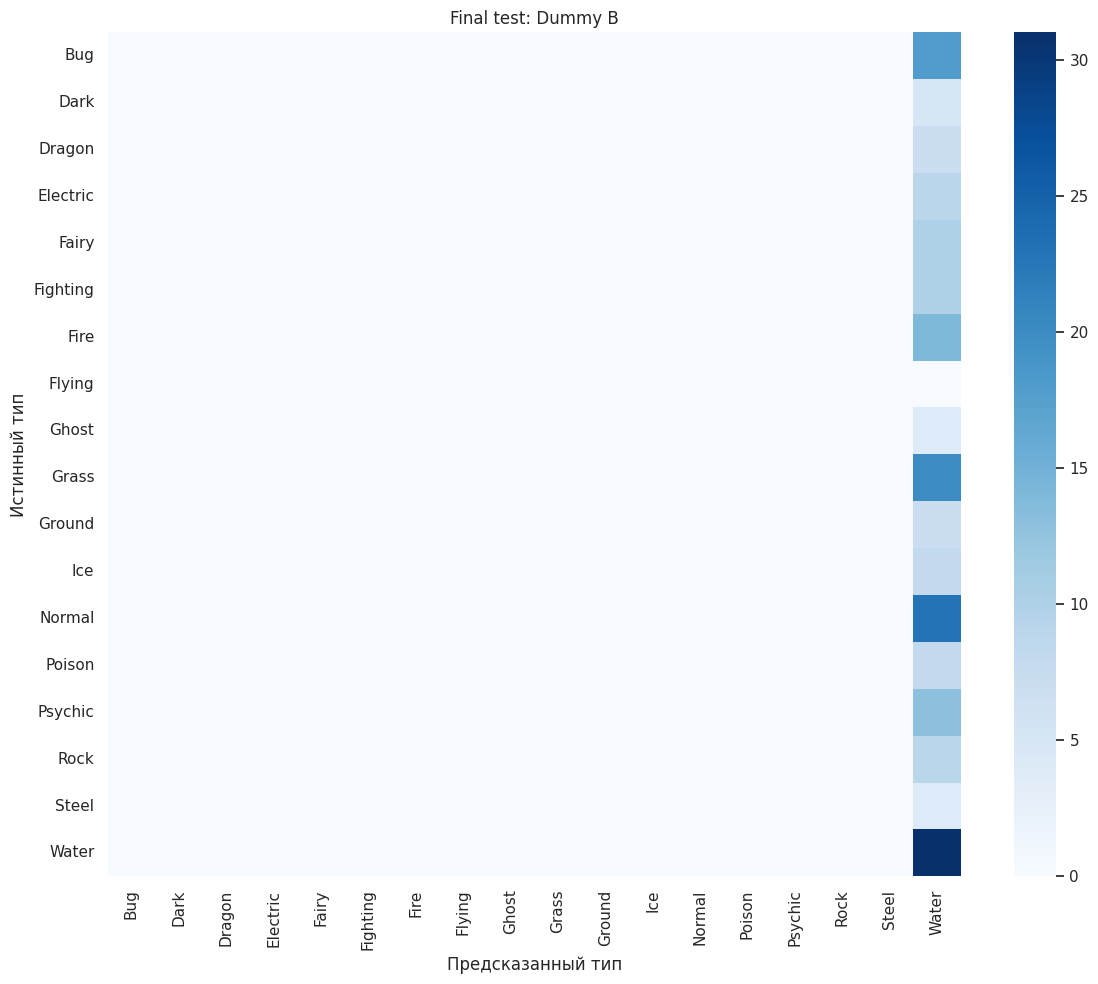


SVM RBF B: метрики типов


,precision,recall,f1-score,support
Bug,0.833,0.556,0.667,18.0
Dark,0.000,0.000,0.000,5.0
Dragon,0.200,0.143,0.167,7.0
Electric,0.077,0.111,0.091,9.0
Fairy,0.400,0.600,0.480,10.0
Fighting,0.188,0.300,0.231,10.0
Fire,0.750,0.857,0.800,14.0
Flying,0.000,0.000,0.000,0.0
Ghost,0.167,0.250,0.200,4.0
Grass,0.467,0.350,0.400,20.0


Ошибок: 127 из 200


,pokedex_number,name,evolution_chain_id,type_1,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,color,shape,prediction
3,19,Rattata,7,Normal,30,56,35,25,35,72,0.3,3.5,purple,quadruped,Poison
6,36,Clefable,14,Fairy,95,70,73,95,90,60,1.3,40.0,pink,upright,Psychic
9,50,Diglett,21,Ground,10,55,25,35,45,95,0.2,0.8,brown,blob,Bug
10,51,Dugtrio,21,Ground,35,100,50,50,70,120,0.7,33.3,brown,heads,Fighting
14,63,Abra,27,Psychic,25,20,15,105,55,90,0.9,19.5,brown,upright,Electric
15,64,Kadabra,27,Psychic,40,35,30,120,70,105,1.3,56.5,brown,upright,Electric
17,74,Geodude,31,Rock,40,80,100,30,30,20,0.4,20.0,brown,arms,Ground
18,75,Graveler,31,Rock,55,95,115,45,45,35,1.0,105.0,brown,humanoid,Steel
19,76,Golem,31,Rock,80,120,130,55,65,45,1.4,300.0,brown,humanoid,Ground
20,81,Magnemite,34,Electric,25,35,70,95,55,45,0.3,6.0,gray,arms,Steel


Самые частые пары ошибок:


count
type_1   prediction       
Electric Dark            4
Normal   Flying          4
Dragon   Fighting        3
Water    Electric        3
         Grass           3
Grass    Ghost           3
Psychic  Electric        3
Water    Steel           3
Normal   Dark            3
Fighting Electric        3

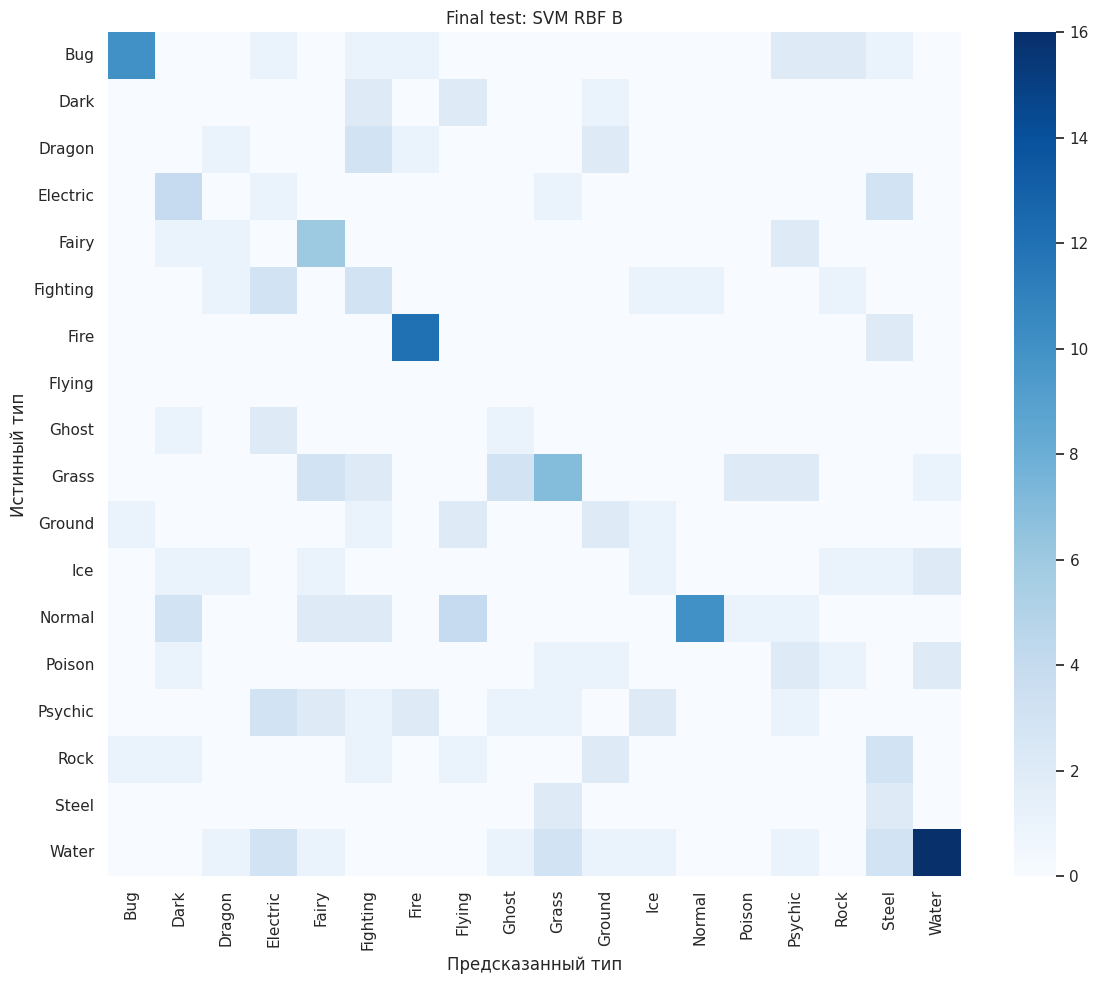


PyTorch MLP B: метрики типов


,precision,recall,f1-score,support
Bug,0.786,0.611,0.688,18.0
Dark,0.000,0.000,0.000,5.0
Dragon,1.000,0.143,0.250,7.0
Electric,0.143,0.111,0.125,9.0
Fairy,0.571,0.400,0.471,10.0
Fighting,0.500,0.300,0.375,10.0
Fire,0.714,0.714,0.714,14.0
Flying,0.000,0.000,0.000,0.0
Ghost,0.125,0.250,0.167,4.0
Grass,0.381,0.400,0.390,20.0


Ошибок: 115 из 200


,pokedex_number,name,evolution_chain_id,type_1,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,color,shape,prediction
3,19,Rattata,7,Normal,30,56,35,25,35,72,0.3,3.5,purple,quadruped,Poison
5,35,Clefairy,14,Fairy,70,45,48,60,65,35,0.6,7.5,pink,upright,Normal
6,36,Clefable,14,Fairy,95,70,73,95,90,60,1.3,40.0,pink,upright,Psychic
9,50,Diglett,21,Ground,10,55,25,35,45,95,0.2,0.8,brown,blob,Bug
10,51,Dugtrio,21,Ground,35,100,50,50,70,120,0.7,33.3,brown,heads,Normal
14,63,Abra,27,Psychic,25,20,15,105,55,90,0.9,19.5,brown,upright,Electric
15,64,Kadabra,27,Psychic,40,35,30,120,70,105,1.3,56.5,brown,upright,Electric
17,74,Geodude,31,Rock,40,80,100,30,30,20,0.4,20.0,brown,arms,Ground
18,75,Graveler,31,Rock,55,95,115,45,45,35,1.0,105.0,brown,humanoid,Ground
19,76,Golem,31,Rock,80,120,130,55,65,45,1.4,300.0,brown,humanoid,Ground


Самые частые пары ошибок:


,,count
type_1,prediction,
Dark,Normal,5
Poison,Water,4
Rock,Ground,4
Water,Grass,4
Grass,Psychic,4
Fairy,Psychic,3
Ground,Poison,3
Fighting,Normal,3
Ice,Water,3


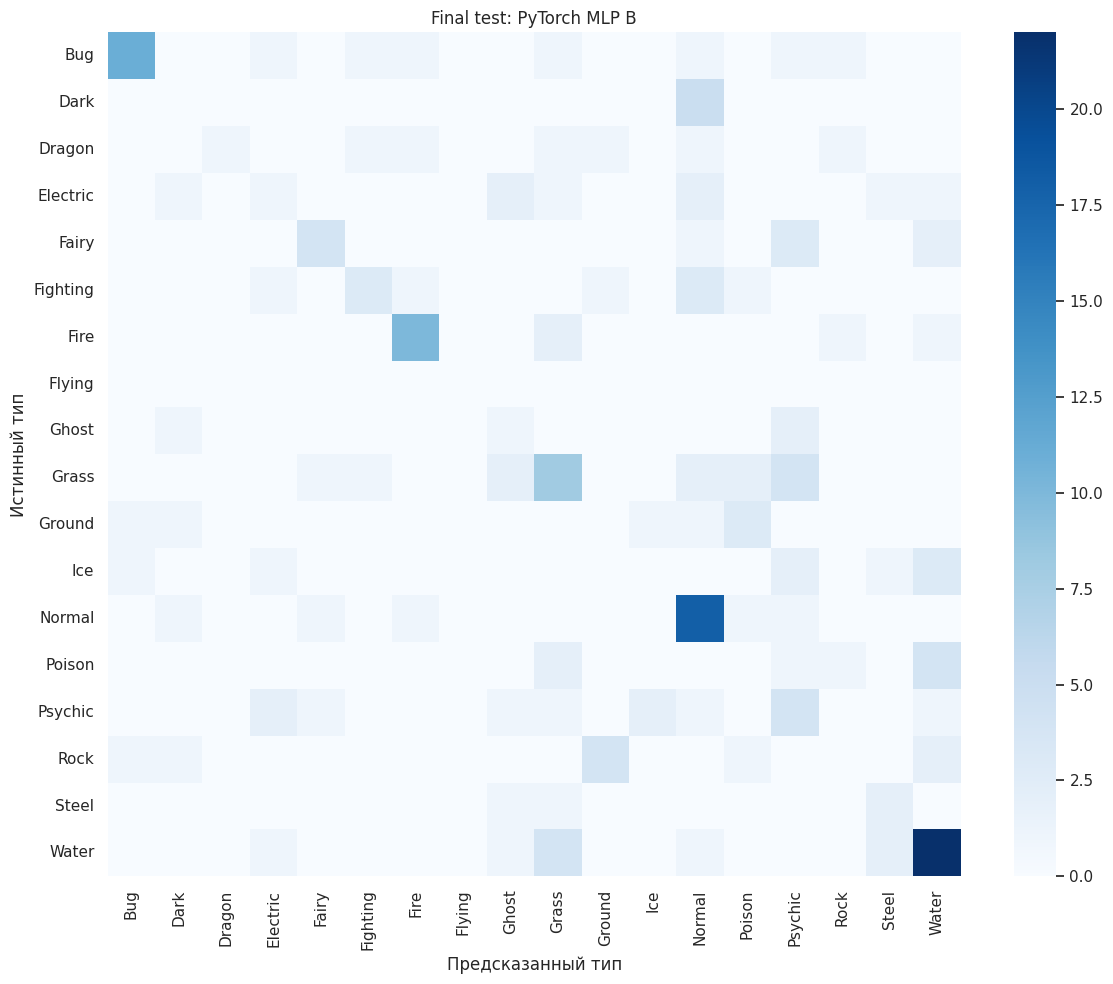


Оценка завершена.
Результаты сохранены: /content/drive/MyDrive/classification_final_test


In [ ]:
if MARKER_PATH.exists():
    raise RuntimeError(
        "Итоговая оценка уже была начата. "
        "Для просмотра результатов загрузите сохранённые CSV. "
        "Не удаляйте маркер для дальнейшего подбора по test."
    )

# До оценки проверяем совместимость preprocessing и сети.
# Используется transform, НЕ fit_transform.
X_test = preprocessor_B.transform(
    test[FEATURES]
).astype("float32")

if X_test.shape[1] != checkpoint["input_dim"]:
    raise ValueError("Размер входа не соответствует checkpoint MLP")

if not np.isfinite(X_test).all():
    raise ValueError("Некорректные значения после preprocessing")

protocol["started_at_utc"] = datetime.now(timezone.utc).isoformat()

# Режим "x" предотвращает случайную перезапись маркера.
with MARKER_PATH.open("x", encoding="utf-8") as file:
    json.dump(protocol, file, ensure_ascii=False, indent=2)

with torch.no_grad():
    logits = mlp_B(torch.from_numpy(X_test).to(DEVICE))
    predicted_ids = logits.argmax(dim=1).cpu().numpy()

predictions = {
    "Dummy B": baseline_B.predict(np.zeros((len(test), 1))),
    "SVM RBF B": svm_B.predict(test[FEATURES]),
    "PyTorch MLP B": encoder_B.inverse_transform(predicted_ids),
}

present_classes = [
    label for label in CLASSES if test_counts[label] > 0
]

metric_rows = []

for model_name, prediction in predictions.items():
    metric_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(test[TARGET], prediction),
        # Средний Recall по типам, присутствующим в test.
        "balanced_accuracy": balanced_accuracy_score(
            test[TARGET], prediction
        ),
        "macro_f1_all_18": f1_score(
            test[TARGET],
            prediction,
            labels=CLASSES,
            average="macro",
            zero_division=0,
        ),
        "macro_f1_present_types": f1_score(
            test[TARGET],
            prediction,
            labels=present_classes,
            average="macro",
            zero_division=0,
        ),
        "weighted_f1": f1_score(
            test[TARGET],
            prediction,
            labels=CLASSES,
            average="weighted",
            zero_division=0,
        ),
        "correct": int((test[TARGET].to_numpy() == prediction).sum()),
        "test_rows": len(test),
    })

results = pd.DataFrame(metric_rows)

# Не выбираем новую модель по test:
# кандидат MLP B зафиксирован ранее по validation.
results.to_csv(
    OUTPUT_DIR / "final_test_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)

prediction_table = test[
    ["pokedex_number", "name", GROUP, TARGET, *FEATURES]
].copy()

for model_name, prediction in predictions.items():
    prediction_table[model_name] = prediction

prediction_table.to_csv(
    OUTPUT_DIR / "final_test_predictions.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Итоговая оценка зафиксированных моделей B:")
display(results.round(4))

for model_name, prediction in predictions.items():
    safe_name = model_name.lower().replace(" ", "_")

    report = pd.DataFrame(
        classification_report(
            test[TARGET],
            prediction,
            labels=CLASSES,
            output_dict=True,
            zero_division=0,
        )
    ).T

    report.to_csv(
        OUTPUT_DIR / f"{safe_name}_report.csv",
        encoding="utf-8-sig",
    )

    print(f"\n{model_name}: метрики типов")
    display(
        report.loc[
            CLASSES,
            ["precision", "recall", "f1-score", "support"],
        ].round(3)
    )

    errors = test[
        ["pokedex_number", "name", GROUP, TARGET, *FEATURES]
    ].copy()

    errors["prediction"] = prediction
    errors = errors.loc[errors[TARGET] != errors["prediction"]]

    errors.to_csv(
        OUTPUT_DIR / f"{safe_name}_errors.csv",
        index=False,
        encoding="utf-8-sig",
    )

    pairs = (
        errors.groupby([TARGET, "prediction"])
        .size()
        .sort_values(ascending=False)
        .rename("count")
    )

    pairs.to_csv(
        OUTPUT_DIR / f"{safe_name}_error_pairs.csv",
        encoding="utf-8-sig",
    )

    print(f"Ошибок: {len(errors)} из {len(test)}")
    display(errors.head(15))

    print("Самые частые пары ошибок:")
    display(pairs.head(10).to_frame())

    matrix = confusion_matrix(
        test[TARGET], prediction, labels=CLASSES
    )

    plt.figure(figsize=(12, 10))
    sns.heatmap(
        matrix,
        xticklabels=CLASSES,
        yticklabels=CLASSES,
        cmap="Blues",
    )
    plt.title(f"Final test: {model_name}")
    plt.xlabel("Предсказанный тип")
    plt.ylabel("Истинный тип")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"{safe_name}_confusion_matrix.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

protocol["completed_at_utc"] = datetime.now(timezone.utc).isoformat()

with (OUTPUT_DIR / "evaluation_completed.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(protocol, file, ensure_ascii=False, indent=2)

print("\nОценка завершена.")
print("Результаты сохранены:", OUTPUT_DIR)

In [ ]:
metrics_path = OUTPUT_DIR / "final_test_metrics.csv"

if metrics_path.is_file():
    display(pd.read_csv(metrics_path).round(4))
else:
    print("Файл итоговых метрик ещё не создан.")

report_path = OUTPUT_DIR / "pytorch_mlp_b_report.csv"

if report_path.is_file():
    report = pd.read_csv(report_path, index_col=0)
    display(report.loc[CLASSES].round(3))

,model,accuracy,balanced_accuracy,macro_f1_all_18,macro_f1_present_types,weighted_f1,correct,test_rows
0,Dummy B,0.155,0.0588,0.0149,0.0158,0.0416,31,200
1,SVM RBF B,0.365,0.3003,0.2736,0.2897,0.3926,73,200
2,PyTorch MLP B,0.425,0.3076,0.2836,0.3002,0.4076,85,200


,precision,recall,f1-score,support
Bug,0.786,0.611,0.688,18.0
Dark,0.000,0.000,0.000,5.0
Dragon,1.000,0.143,0.250,7.0
Electric,0.143,0.111,0.125,9.0
Fairy,0.571,0.400,0.471,10.0
Fighting,0.500,0.300,0.375,10.0
Fire,0.714,0.714,0.714,14.0
Flying,0.000,0.000,0.000,0.0
Ghost,0.125,0.250,0.167,4.0
Grass,0.381,0.400,0.390,20.0


До выполнения итоговой оценки зафиксированы модели SVM и PyTorch MLP из эксперимента B, использующие боевые характеристики, рост, вес, цвет и форму тела. Вариант MLP с весами классов из эксперимента C отклонён, поскольку не улучшил основную метрику на validation. Предпочтительным кандидатом по validation является MLP B, однако её преимущество над SVM по macro-F1 минимально.

Итоговая оценка проводится на сохранённой тестовой выборке без повторного обучения и подбора параметров. После просмотра результатов test настройки не изменяются. Тип Flying отсутствует в тестовой выборке, поэтому его качество отдельно не оценено.